In [25]:
# Reloads modules before code execution
# Data is loaded by @src/ so if changed want notebook to reload
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [26]:
# Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [27]:
from super_store.data import load

# Data Exploration
df = load()
print("Head\n", df.head())
print("Overview", df.info())
print("Statistics\n", df.describe())

Head
           Category         City        Country Customer ID     Customer Name  \
0  Office Supplies  Los Angeles  United States   LS-172304  Lycoris Saunders   
1  Office Supplies  Los Angeles  United States   MV-174854     Mark Van Huff   
2  Office Supplies  Los Angeles  United States   CS-121304      Chad Sievert   
3  Office Supplies  Los Angeles  United States   CS-121304      Chad Sievert   
4  Office Supplies  Los Angeles  United States   AP-109154    Arthur Prichep   

   Discount Market  ji_lu-shu Order Date        Order ID  ...   Segment  \
0       0.0     US          1    00:00.0  CA-2011-130813  ...  Consumer   
1       0.0     US          1    00:00.0  CA-2011-148614  ...  Consumer   
2       0.0     US          1    00:00.0  CA-2011-118962  ...  Consumer   
3       0.0     US          1    00:00.0  CA-2011-118962  ...  Consumer   
4       0.0     US          1    00:00.0  CA-2011-146969  ...  Consumer   

  Ship Date       Ship Mode  Shipping Cost       State Sub-Cat

In [28]:
# Data Cleaning

# Row ID is unique per row, so ignore it when looking for duplicates
dup_cols = df.columns.drop('Row ID')
print("Duplicate rows:", df.duplicated(subset=dup_cols).sum())
df = df.drop_duplicates(subset=dup_cols, ignore_index=True)

print("Missing values:", df.isna().sum().sum())

# ji_lu-shu ("record count") is 1 on every row, so it carries no information
df = df.drop(columns='ji_lu-shu')

Duplicate rows: 0
Missing values: 0


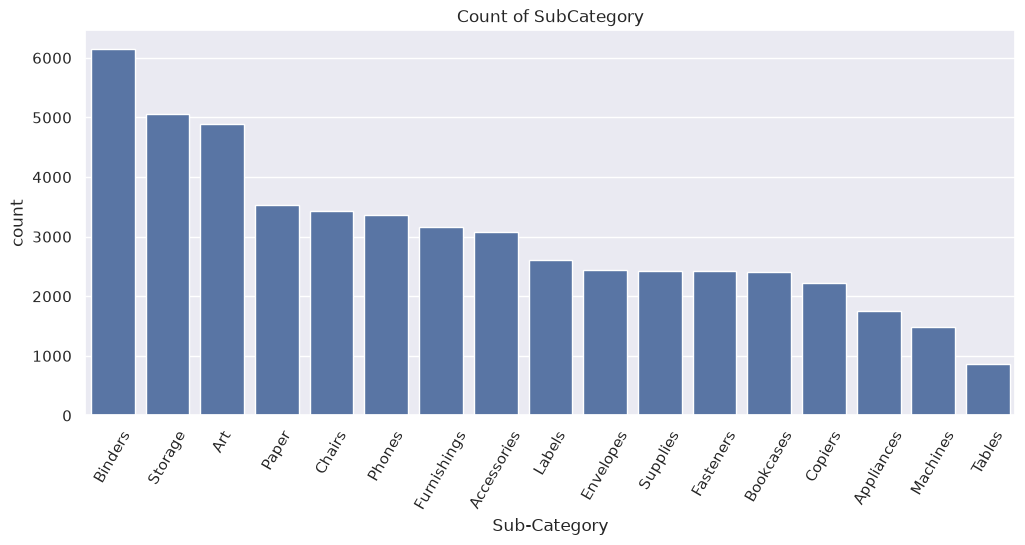

In [29]:
sns.set_theme(rc={'figure.figsize':(12,5)})
order = df['Sub-Category'].value_counts().index
sns.countplot(data=df, x='Sub-Category', order=order)
plt.xticks(rotation=60)
plt.title('Count of SubCategory')
plt.show()

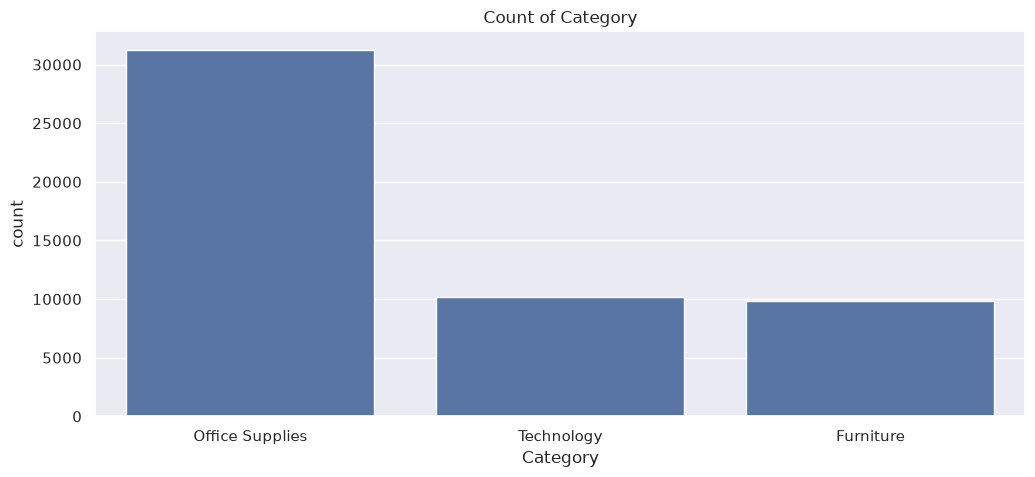

In [30]:
sns.countplot(x='Category', data=df)
plt.title('Count of Category')
plt.show()

In [31]:
df2 = pd.DataFrame(df.groupby('Segment').Profit.mean())
df2

,Profit
Segment,
Consumer,28.254008
Corporate,28.596042
Home Office,29.648847


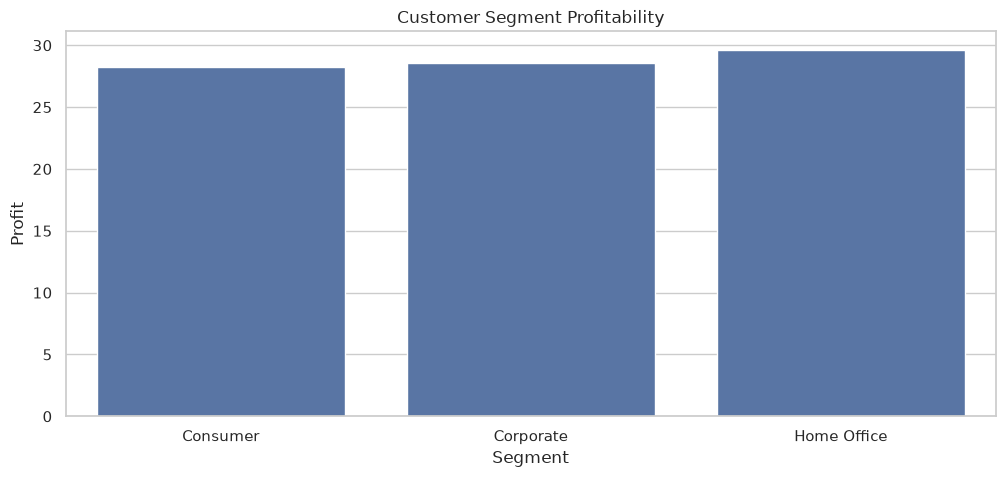

In [32]:
sns.set_theme(style="whitegrid")
sns.barplot(data = df2, x = df2.index, y = df2['Profit'])
plt.title("Customer Segment Profitability")
plt.show()

In [33]:
region_analysis = pd.DataFrame(df.groupby(['Region'])['Profit'].sum().reset_index())
region_analysis

,Region,Profit
0,Africa,88871.63100
1,Canada,17817.39000
2,Caribbean,34571.32104
3,Central,311403.98164
4,Central Asia,132480.18700
5,EMEA,43897.97100
6,East,91522.78000
7,North,194597.95252
8,North Asia,165578.42100
9,Oceania,120089.11200


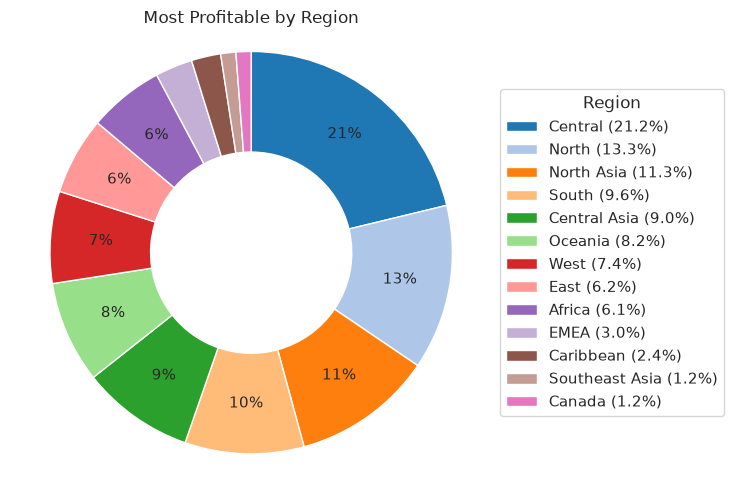

In [34]:
# Sort so slices run largest to smallest clockwise from the top
pie_data = region_analysis.sort_values('Profit', ascending=False)
shares = pie_data.Profit / pie_data.Profit.sum() * 100

fig, ax = plt.subplots(figsize=(7.5, 5))
wedges, texts, autotexts = ax.pie(
    pie_data.Profit,
    startangle=90,
    counterclock=False,
    colors=sns.color_palette('tab20', len(pie_data)),
    # Hide labels on tiny slices; the legend shows every region's share
    autopct=lambda pct: f'{pct:.0f}%' if pct >= 3 else '',
    pctdistance=0.75,
    wedgeprops=dict(width=0.5, edgecolor='white'),
    textprops=dict(fontsize=11),
)

ax.legend(wedges, [f'{r} ({s:.1f}%)' for r, s in zip(pie_data.Region, shares)],
          title='Region', loc='center left', bbox_to_anchor=(1, 0.5))
ax.set_title('Most Profitable by Region')
ax.axis('equal')
plt.tight_layout()
plt.show()